# M11: Protection, rewiring and recovery

**Paper section covered:** none; this tests the paper's own conclusion and its "future work". Extensions E9 and E10.

## The paper's recommendation
The paper ends with one concrete piece of advice: "**Protecting key hub airports is important to make the network more robust and prevent large-scale failures**", and lists as future work "optimization strategies like a new route or decentralizing traffic". Nothing in the paper tests it. We now have three different ways in which the network can fail (targeted attack, M5; threshold cascade, M6; load cascade, M9), so we can ask:

1. **Protection.** If a budget lets us "harden" k airports (they cannot be attacked or fail), *which* airports should they be? Does protecting hubs work, against which failure model, and is a hub-based rule the best?
2. **Capacity allocation.** For the load cascade, how much spare capacity is needed, and how much cheaper is it to put it where it matters?
3. **Rewiring.** If a budget lets us add m new routes, which routes make the network more robust?
4. **Recovery.** After a failure, in which order should airports be restored?

## How protection is modelled
A **protected** airport (i) cannot be removed by an attacker (the attacker takes the next-best unprotected target), (ii) cannot fail in a threshold cascade (it needs more failed neighbours than it has), (iii) has unlimited capacity in a load cascade, and in the cascades it cannot be the origin of a failure either. Protection is deliberately idealised: it measures how much *could* be gained, not what hardening costs.

## Metrics
| Failure model | How we measure the benefit of protection |
|---|---|
| Targeted attack | Robustness index R of the largest component against three attackers: degree (ranked once), betweenness (ranked once), and **adaptive betweenness** (re-ranked after each removal, the strongest from M5). Higher = more robust |
| Threshold cascade | Share of the unprotected origins whose failure collapses the network (final largest component at most half) at threshold 0.15 and 0.10. Lower = safer |
| Load cascade | Number of unprotected origins that collapse the network at spare capacity 0 and 0.1. Lower = safer |

## Plan
| Part | Content |
|---|---|
| A | Which airports? Eleven ranking rules, and a greedy rule |
| B | Protection against targeted attacks |
| C | Protection against the two cascade models; does a rule transfer? |
| D | Budgeted capacity allocation |
| E | Rewiring: which new routes help? |
| F | Recovery order |
| G | Verdict: is "protect the hubs" right? |

## 1. Setup

In [1]:
import sys, warnings, time
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve().parent
sys.path.insert(0, str(ROOT / "src"))
import usfn, weighted as wt, cascade as cs, load_cascade as lc, resilience as rs

warnings.filterwarnings("ignore")
pd.set_option("display.width", 185)
pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})
BLUE, RED, GREEN, ORANGE, GREY, PURPLE, TEAL, BROWN, PINK = "#3b6ea5", "#c05746", "#4d8f5b", "#d99a2b", "#777777", "#8e5ea2", "#17a2b8", "#8c564b", "#e377c2"
rng = np.random.default_rng(2025)

airports, routes = usfn.load_openflights()
G0 = usfn.build_country_network(airports, routes)
G, Gop, cshare = wt.build_weightings(G0, routes)
nodes = list(G.nodes); N = len(nodes); idx = {n: i for i, n in enumerate(nodes)}
deg = dict(G.degree()); strength = dict(G.degree(weight="weight"))

t0 = time.time()
LC = lc.LoadCascade(G); EV = rs.LoadEvaluator(LC)
C = cs.Cascade(G)
print(f"USFN: {N} airports; engines ready in {time.time() - t0:.0f} s")

# sanity: the protection machinery reproduces the earlier milestones when nothing is protected
base_adapt = rs.attack_curve(G, [], "betweenness_adaptive", nodes)
base_summary = EV.summary(LC.capacity(0.1))
print(f"unprotected: adaptive-betweenness attack R = {rs.robustness_R(base_adapt, N):.3f} (M5: 0.036); load cascade at alpha = 0.1: {base_summary['dangerous']} dangerous origins (M9: 5)")

USFN: 541 airports; engines ready in 8 s


unprotected: adaptive-betweenness attack R = 0.036 (M5: 0.036); load cascade at alpha = 0.1: 5 dangerous origins (M9: 5)


## Part A. Which airports to protect?

Eleven ranking rules, grouped by what they know:

| Rule | Idea |
|---|---|
| degree, closeness, PageRank | classic centralities |
| strength | weighted degree with the paper's weights (M7) |
| betweenness (= load) | how much shortest-path traffic goes through the airport |
| **threshold danger** | airports whose own failure is most dangerous in the threshold cascade (M6: own critical threshold) |
| **load danger** | airports whose own failure is most dangerous in the load cascade (M9: own critical spare capacity) |
| **threshold victims** | airports that fail most often across all origins in the threshold cascade (t = 0.15) |
| **load victims** | airports that fail most often by overload across all origins (alpha = 0.1, as in M9 Part G) |
| random | the baseline (average of 20 random draws) |

The danger and victim rules need a cascade model; the others only need the map.

In [2]:
t0 = time.time()
# threshold danger (own critical threshold, M6) and threshold victims (failures at t = 0.15)
tg = np.round(np.arange(0.02, 0.4001, 0.005), 3)
t_c = np.zeros(N)
for i in range(N):
    ok = [t for t in tg if C.run([i], C.need(t))[0].sum() >= 0.5 * N]; t_c[i] = max(ok) if ok else 0.0
need15 = C.need(0.15)
thr_victim = np.zeros(N)
for i in range(N):
    f = C.run([i], need15)[0]; f[i] = False; thr_victim += f
# load danger (own critical spare capacity, M9) and load victims (overload failures at alpha = 0.1)
al = np.round(np.arange(0, 1.0001, 0.05), 3)
a_c = -np.ones(N)
for a in al:
    origins, fin = EV.evaluate(LC.capacity(a))
    a_c[origins[fin <= N / 2]] = np.maximum(a_c[origins[fin <= N / 2]], a)
cap01 = LC.capacity(0.1); load_victim = np.zeros(N)
for s in range(N):
    act = np.ones(N, dtype=bool); act[s] = False
    if (act & (EV.L1[s] > cap01 * (1 + 1e-9) + 1e-9)).any():
        r = LC.run(s, cap01)
        for f in r["failed_by_round"]: load_victim[f] += 1
print(f"rankings computed in {time.time() - t0:.0f} s")

bc_ = pd.Series(LC.L0, index=nodes)
def by(score, tie=None):
    s_ = pd.Series(score, index=nodes); t_ = pd.Series(tie if tie is not None else [deg[n] for n in nodes], index=nodes)
    return list(pd.DataFrame({"s": s_, "t": t_}).sort_values(["s", "t"], ascending=False).index)
rules = {
    "degree": by([deg[n] for n in nodes]),
    "closeness": by(list(nx.closeness_centrality(G).values())),
    "PageRank": by(list(nx.pagerank(G, weight=None).values())),
    "strength (paper weights)": by([strength[n] for n in nodes]),
    "betweenness / load": by(LC.L0),
    "threshold danger": by(t_c),
    "load danger": by(a_c, tie=LC.L0),
    "threshold victims": by(thr_victim),
    "load victims": by(load_victim, tie=LC.L0),
}
top = pd.DataFrame({k: v[:10] for k, v in rules.items()}); top.index = range(1, 11); top.index.name = "rank"
top

rankings computed in 24 s


,degree,closeness,PageRank,strength (paper weights),betweenness / load,threshold danger,load danger,threshold victims,load victims
rank,,,,,,,,,
1,ATL,DEN,DEN,ATL,ANC,LAS,ORD,CEM,PIE
2,ORD,ORD,ATL,ORD,DEN,MSP,DEN,IRC,SFB
3,DEN,MSP,ORD,DFW,ORD,DFW,MSP,MLY,PGD
4,DFW,LAS,DFW,DEN,SEA,ATL,LAS,WBQ,MIA
5,MSP,SEA,MSP,LAX,ATL,SFB,LAX,PIZ,ORD
6,DTW,LAX,LAS,CLT,MSP,PIE,SEA,LMA,TPA
7,LAS,PHX,DTW,PHX,DFW,FLL,DFW,FAI,MCO
8,CLT,SLC,CLT,PHL,BET,IAH,SLC,BRW,MDW
9,IAH,ATL,IAH,LAS,FAI,DEN,PHX,GAL,MYR


**Reading this.** The rules pick very different airports. The classic centralities (degree, strength, PageRank, closeness) all pick the big hubs (ATL, ORD, DEN, DFW, MSP...). Betweenness/load puts the Alaskan gateways ANC, BET and FAI next to SEA and the biggest hubs. The cascade-based rules pick yet other airports: the **danger** rules choose airports whose own failure would be worst (LAS, MSP, DFW, ATL, DEN, ORD...), the **load-victim** rule chooses small and mid-sized leisure airports (PIE, SFB, PGD, MIA...) that overload most often when something else breaks (as found in M9), and the **threshold-victim** rule chooses tiny Alaskan airports (CEM, IRC, MLY, WBQ...) that fail whenever their one or two neighbours fail. If "protect the hubs" were the whole story these lists would coincide; they do not.

## Part B. Protection against targeted attacks

Protect the top k airports of each rule (k = 5, 10, 20, 40) and let the three attackers remove as many *unprotected* airports as they like. We report the robustness index R (the average size of the largest component over all removals, as a fraction of the network); the unprotected values are 0.062 (degree), 0.061 (betweenness) and 0.036 (adaptive betweenness), and random failure gives 0.39.

In [3]:
ks = (5, 10, 20, 40)
attackers = ["degree", "betweenness", "betweenness_adaptive"]
def eval_attack(prot):
    return {a: rs.robustness_R(rs.attack_curve(G, prot, a, nodes), N) for a in attackers}

rows = []
for rule, order in rules.items():
    for k in ks:
        e = eval_attack(order[:k]); rows.append({"rule": rule, "k": k, **{f"R {a}": e[a] for a in attackers}})
for k in ks:                                                                  # random protection: average of 20 draws
    es = [eval_attack(list(rng.choice(nodes, k, replace=False))) for _ in range(20)]
    rows.append({"rule": "random", "k": k, **{f"R {a}": np.mean([x[a] for x in es]) for a in attackers}})
att = pd.DataFrame(rows)
base_R = {a: rs.robustness_R(rs.attack_curve(G, [], a, nodes), N) for a in attackers}
print("unprotected R:", {a: round(v, 3) for a, v in base_R.items()})
piv = att.pivot(index="rule", columns="k", values="R betweenness_adaptive")[list(ks)]
print("adaptive-betweenness attacker, R by rule (rows) and number of protected airports (columns):")
display(piv.sort_values(10, ascending=False).style.format("{:.3f}").background_gradient(cmap="Greens", axis=None))

unprotected R: {'degree': 0.062, 'betweenness': 0.061, 'betweenness_adaptive': 0.036}
adaptive-betweenness attacker, R by rule (rows) and number of protected airports (columns):


k,5,10,20,40
rule,,,,
betweenness / load,0.256,0.309,0.403,0.490
PageRank,0.255,0.305,0.386,0.463
closeness,0.227,0.300,0.363,0.427
strength (paper weights),0.259,0.297,0.340,0.407
degree,0.255,0.288,0.362,0.417
load danger,0.232,0.286,0.326,0.354
threshold danger,0.179,0.261,0.321,0.365
load victims,0.118,0.124,0.200,0.329
random,0.048,0.063,0.067,0.127


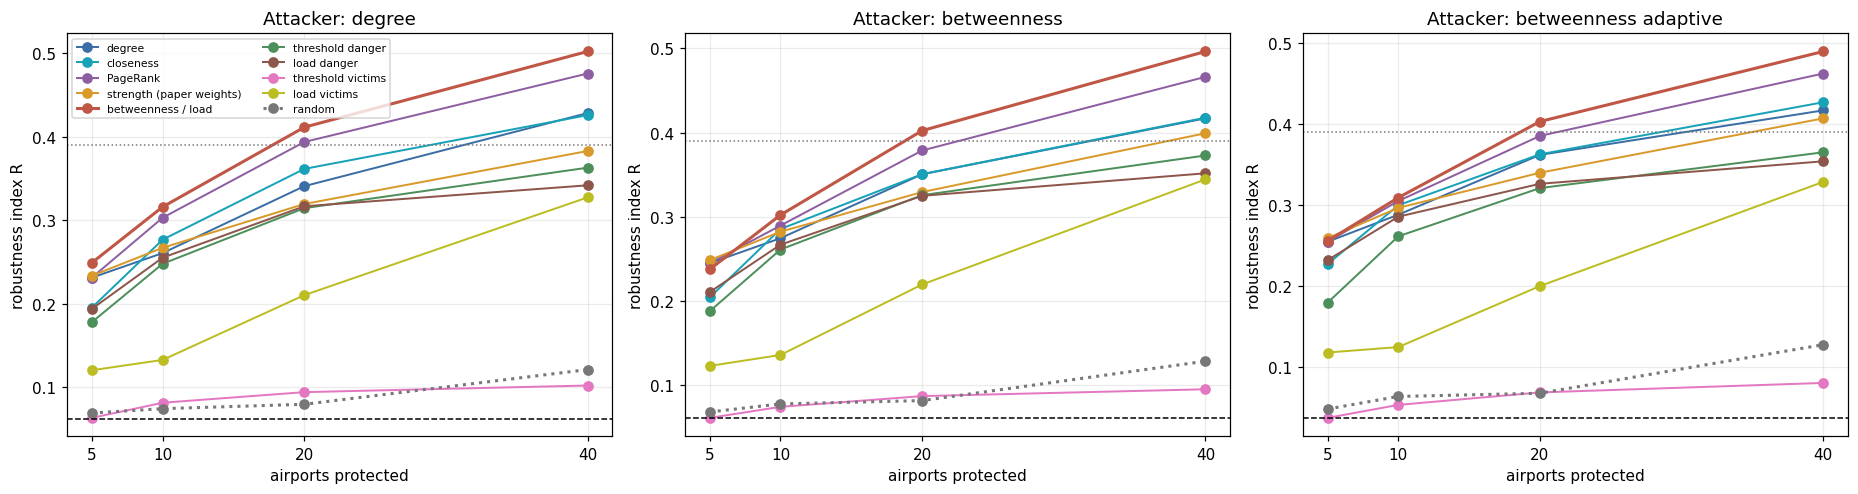

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
colors = dict(zip(list(rules) + ["random"], [BLUE, TEAL, PURPLE, ORANGE, RED, GREEN, BROWN, PINK, "#bcbd22", GREY]))
for ax, a in zip(axes, attackers):
    for rule in list(rules) + ["random"]:
        d = att[att.rule == rule]; ax.plot(d.k, d[f"R {a}"], "o-", color=colors[rule], lw=2 if rule in ("betweenness / load", "random") else 1.3, label=rule, ls=":" if rule == "random" else "-")
    ax.axhline(base_R[a], color="black", ls="--", lw=1); ax.axhline(0.39, color=GREY, ls=":", lw=1)
    ax.set_xlabel("airports protected"); ax.set_ylabel("robustness index R"); ax.set_title(f"Attacker: {a.replace('_', ' ')}"); ax.set_xticks(ks)
axes[0].legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.show()

**Reading this.** Protection works, and works fast, **against the adaptive attacker**: protecting only 5 to 10 airports by betweenness lifts the robustness index from 0.036 to 0.26 to 0.31 (seven to eight times), and protecting 20 brings it to 0.40, about the level of random failure (0.39); protecting 40 by betweenness gives 0.49, above random failure. The informed centralities are close to each other (at k = 10: betweenness 0.309, PageRank 0.305, closeness 0.300, strength 0.297, degree 0.288; at k = 40 betweenness 0.490 against degree 0.417), so degree is a good but slightly weaker choice. The cascade-derived rules are weaker against attacks (threshold danger 0.261, load danger 0.286, load victims 0.124 at k = 10), and the **victim** rules are useless here: threshold victims give 0.053 and random protection 0.063 at k = 10. We show only the adaptive attacker here; the static attackers are covered by the checks below.

## Part C. Protection against the two cascade models

In [5]:
def eval_threshold(prot, ts=(0.10, 0.15)):
    pr = np.zeros(N, dtype=bool); pr[[idx[p] for p in prot]] = True
    out = {}
    for t in ts:
        need = C.need(t).copy(); need[pr] = N + 1
        fin = np.array([C.run([i], need)[0].sum() for i in range(N) if not pr[i]])
        out[f"threshold t={t}"] = float((fin >= 0.5 * N).mean())
    return out
def eval_load(prot, alphas=(0.0, 0.1)):
    pi = [idx[p] for p in prot]; out = {}
    for a in alphas:
        s = EV.summary(LC.capacity(a), pi); out[f"load alpha={a}"] = s["dangerous"]
    return out

t0 = time.time(); rows = []
for rule, order in rules.items():
    for k in ks:
        rows.append({"rule": rule, "k": k, **eval_threshold(order[:k]), **eval_load(order[:k])})
for k in ks:
    es = [{**eval_threshold(list(rng.choice(nodes, k, replace=False))), **eval_load(list(rng.choice(nodes, k, replace=False)))} for _ in range(8)]
    rows.append({"rule": "random", "k": k, **{c: np.mean([e[c] for e in es]) for c in es[0]}})
cas = pd.DataFrame(rows)
print(f"cascade evaluations in {time.time() - t0:.0f} s")
base_thr = eval_threshold([]); base_load = eval_load([])
print("unprotected:", {k: (round(v, 3) if isinstance(v, float) else v) for k, v in {**base_thr, **base_load}.items()})
for col, title in [("threshold t=0.15", "threshold cascade: share of origins collapsing the network (t = 0.15), lower is better"), ("load alpha=0.0", "load cascade: dangerous origins with no spare capacity, lower is better"), ("load alpha=0.1", "load cascade: dangerous origins with 10% spare capacity, lower is better")]:
    print("\n" + title)
    display(cas.pivot(index="rule", columns="k", values=col)[list(ks)].sort_values(10).style.format("{:.3f}" if "threshold" in col else "{:.1f}"))

cascade evaluations in 473 s


unprotected: {'threshold t=0.1': 0.074, 'threshold t=0.15': 0.017, 'load alpha=0.0': 40, 'load alpha=0.1': 5}

threshold cascade: share of origins collapsing the network (t = 0.15), lower is better


k,5,10,20,40
rule,,,,
PageRank,0.007,0.000,0.000,0.000
degree,0.007,0.000,0.000,0.000
threshold danger,0.002,0.000,0.000,0.000
betweenness / load,0.013,0.006,0.000,0.000
closeness,0.011,0.006,0.000,0.000
strength (paper weights),0.009,0.006,0.000,0.000
load danger,0.011,0.008,0.000,0.000
load victims,0.011,0.011,0.006,0.000
random,0.016,0.014,0.014,0.012



load cascade: dangerous origins with no spare capacity, lower is better


k,5,10,20,40
rule,,,,
PageRank,0.0,0.0,0.0,0.0
betweenness / load,0.0,0.0,0.0,0.0
closeness,0.0,0.0,0.0,0.0
degree,0.0,0.0,0.0,0.0
load danger,1.0,0.0,0.0,0.0
strength (paper weights),0.0,0.0,0.0,0.0
threshold danger,1.0,0.0,0.0,0.0
load victims,6.0,5.0,6.0,0.0
random,39.2,35.2,41.0,29.8



load cascade: dangerous origins with 10% spare capacity, lower is better


k,5,10,20,40
rule,,,,
PageRank,0.0,0.0,0.0,0.0
betweenness / load,0.0,0.0,0.0,0.0
closeness,0.0,0.0,0.0,0.0
degree,0.0,0.0,0.0,0.0
load danger,0.0,0.0,0.0,0.0
load victims,0.0,0.0,0.0,0.0
strength (paper weights),0.0,0.0,0.0,0.0
threshold danger,0.0,0.0,0.0,0.0
random,5.0,4.1,5.6,3.4


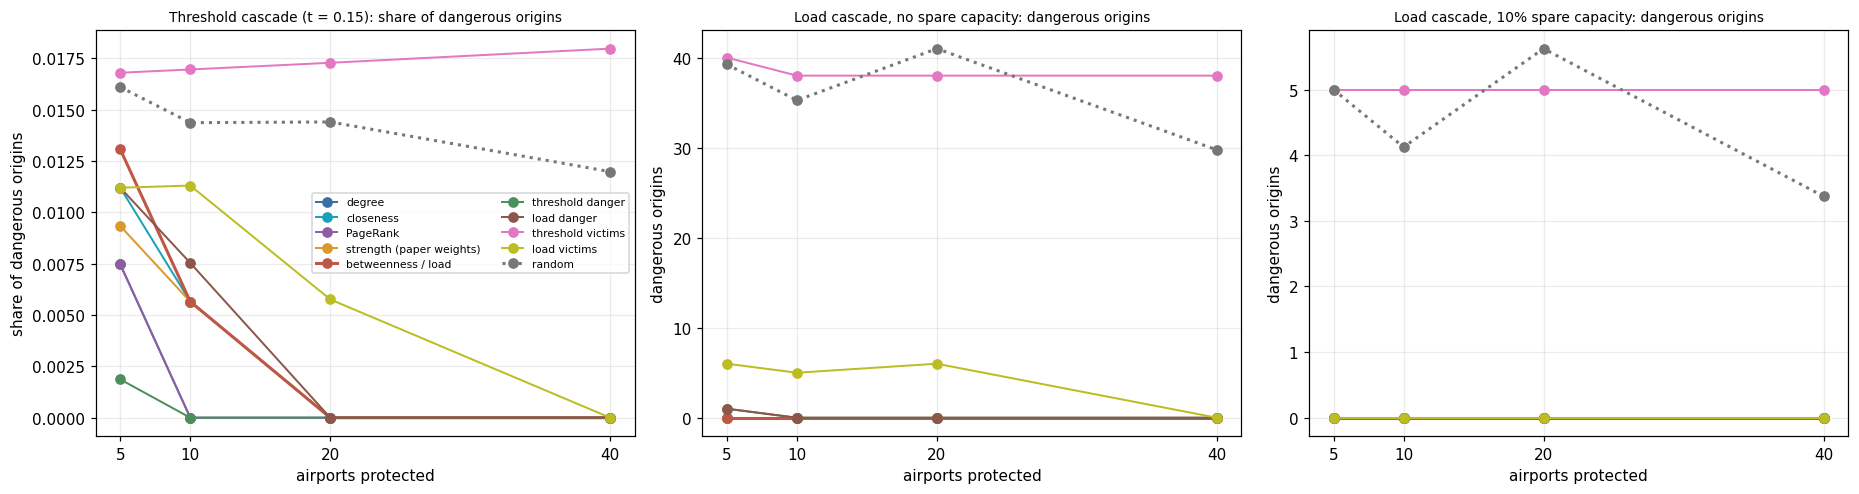

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for ax, col, ttl in [(axes[0], "threshold t=0.15", "Threshold cascade (t = 0.15): share of dangerous origins"), (axes[1], "load alpha=0.0", "Load cascade, no spare capacity: dangerous origins"), (axes[2], "load alpha=0.1", "Load cascade, 10% spare capacity: dangerous origins")]:
    for rule in list(rules) + ["random"]:
        d = cas[cas.rule == rule]; ax.plot(d.k, d[col], "o-", color=colors[rule], lw=2 if rule in ("betweenness / load", "random") else 1.3, label=rule, ls=":" if rule == "random" else "-")
    ax.set_xlabel("airports protected"); ax.set_ylabel(ttl.split(":")[1].strip()); ax.set_title(ttl, fontsize=9); ax.set_xticks(ks)
axes[0].legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.show()

**Reading this.** The picture is **different for each cascade model**, and both cascades are easy to defend:
- In the **threshold** cascade only 1.7% of origins (9 of 541) collapse the network at t = 0.15 without protection (7.4% at t = 0.10). Protecting 10 airports by degree or PageRank (or the threshold-danger rule, which already needs only 5) removes all of them; betweenness and closeness leave 3 origins at k = 10 and clear them at k = 20. The **victim** rule does nothing (0.017 at every k, even worse than random protection, 0.014) because the victims are tiny airports that are not the cause of the cascades.
- In the **load** cascade without spare capacity, 40 origins can collapse the network. Protecting 5 airports by degree, PageRank, betweenness, closeness or strength removes **all** of them. Part of this is by construction: protected airports cannot be origins, and the dangerous origins are the high-load airports themselves. The rules that do not pick those airports are far less effective: load victims leave 5 to 6 dangerous origins up to k = 20, random protection leaves 30 to 41, and threshold victims leave 38 to 40. With 10% spare capacity (5 dangerous origins) every informed rule gets to zero at k = 5.
- Which rule is best depends on the model (transfer matrix below): betweenness is best against attacks but ranks only sixth on the threshold cascade, while degree and PageRank are the best for the threshold cascade. The differences on the two cascade criteria are small (one to three origins) because most rules reach zero.

### C2. A greedy rule
The rules above are ranked lists. A **greedy** rule instead picks airports one at a time, each time the one that most reduces the damage of the failure model *given the airports already protected*. It is expensive, so we restrict the candidates (the 20 to 30 most frequent victims and the 10 to 15 highest-load or most dangerous airports) and the objective (the origins that actually cause large cascades), and evaluate the result on all origins.

In [7]:
t0 = time.time()
# ---- greedy for the load cascade: objective = total damage of the origins that collapse the network at alpha = 0.05
a_g = 0.05; capg = LC.capacity(a_g)
base_origins, base_fin = EV.evaluate(capg)
targets = [int(s) for s, f in zip(base_origins, base_fin) if f <= 0.5 * N]
pool = list(dict.fromkeys([idx[n] for n in rules["load victims"][:20]] + [idx[n] for n in rules["betweenness / load"][:15]]))
def damage(prot_idx):
    _, fin = EV.evaluate(capg, prot_idx, origins=[s for s in targets if s not in prot_idx])
    return float((N - fin).sum())
prot, greedy_load = [], []
for step in range(20):
    best, bestv = None, None
    for c in pool:
        if c in prot: continue
        v = damage(prot + [c])
        if bestv is None or v < bestv: best, bestv = c, v
    prot.append(best); greedy_load.append(nodes[best])
print(f"greedy load protection ({len(targets)} target origins at alpha = {a_g}): {greedy_load[:10]} ({time.time() - t0:.0f} s)")

# ---- greedy for the threshold cascade: objective = number of origins collapsing the network at t = 0.15 (then mean failed fraction)
t0 = time.time()
poolt = list(dict.fromkeys([idx[n] for n in rules["threshold victims"][:30]] + [idx[n] for n in rules["threshold danger"][:10]]))
def thr_obj(prot_idx):
    pr = np.zeros(N, dtype=bool); pr[prot_idx] = True; need = need15.copy(); need[pr] = N + 1
    fin = np.array([C.run([i], need)[0].sum() for i in range(N) if not pr[i]])
    return (fin >= 0.5 * N).sum() + fin.mean() / N
prot, greedy_thr = [], []
for step in range(20):
    best, bestv = None, None
    for c in poolt:
        if c in prot: continue
        v = thr_obj(prot + [c])
        if bestv is None or v < bestv: best, bestv = c, v
    prot.append(best); greedy_thr.append(nodes[best])
print(f"greedy threshold protection: {greedy_thr[:10]} ({time.time() - t0:.0f} s)")
rules["greedy (load model)"] = greedy_load; rules["greedy (threshold model)"] = greedy_thr

greedy load protection (10 target origins at alpha = 0.05): ['ORD', 'LAS', 'SEA', 'DEN', 'DFW', 'MSP', 'LAX', 'SLC', 'DAL', 'PIE'] (99 s)


greedy threshold protection: ['PIE', 'DFW', 'DEN', 'MSP', 'ATL', 'LAS', 'FAI', 'OME', 'SCC', 'HSL'] (6 s)


In [8]:
gk = (5, 10, 20)
rows = []
for rule in ("greedy (load model)", "greedy (threshold model)"):
    for k in gk:
        rows.append({"rule": rule, "k": k, **{f"R {a}": v for a, v in eval_attack(rules[rule][:k]).items()}, **eval_threshold(rules[rule][:k]), **eval_load(rules[rule][:k])})
gdf = pd.DataFrame(rows)
cmp_ = pd.concat([att[att.rule.isin(["betweenness / load", "threshold danger", "load danger", "degree", "random"]) & att.k.isin(gk)].merge(cas, on=["rule", "k"]), gdf]).sort_values(["k", "rule"])
cmp_ = cmp_[["k", "rule", "R betweenness_adaptive", "threshold t=0.15", "load alpha=0.0", "load alpha=0.1"]]
cmp_.columns = ["k", "rule", "attack R (adaptive)", "threshold share (t=0.15)", "load dangerous (alpha=0)", "load dangerous (alpha=0.1)"]
cmp_.style.hide(axis="index").format({"attack R (adaptive)": "{:.3f}", "threshold share (t=0.15)": "{:.3f}", "load dangerous (alpha=0)": "{:.1f}", "load dangerous (alpha=0.1)": "{:.1f}"})

k,rule,attack R (adaptive),threshold share (t=0.15),load dangerous (alpha=0),load dangerous (alpha=0.1)
5,betweenness / load,0.256,0.013,0.0,0.0
5,degree,0.255,0.007,0.0,0.0
5,greedy (load model),0.239,0.009,0.0,0.0
5,greedy (threshold model),0.226,0.002,4.0,0.0
5,load danger,0.232,0.011,1.0,0.0
5,random,0.048,0.016,39.2,5.0
5,threshold danger,0.179,0.002,1.0,0.0
10,betweenness / load,0.309,0.006,0.0,0.0
10,degree,0.288,0.000,0.0,0.0
10,greedy (load model),0.267,0.002,0.0,0.0


**Reading this.** The greedy rules do **not** beat the simple rules: with 5 protected airports the load-greedy rule leaves no dangerous origin (as do the simple hub rules), and the threshold-greedy rule leaves a share of 0.002 for the threshold cascade (the simple hub rules leave 0.007 to 0.013 at k = 5), but it leaves 4 dangerous origins in the load cascade (2 at k = 10) where hub rules leave none. Against the adaptive attacker the greedy rules are weaker than betweenness (R 0.239 and 0.226 against 0.256 at k = 5; 0.267 and 0.231 against 0.309 at k = 10). Tailoring a rule to one model buys at most a small gain on that model and costs protection against the others. The simple global centralities are close to the best.

### C3. Does a rule transfer? The summary matrix (k = 10)
The table ranks the rules, at 10 protected airports, on each of the four criteria (1 = best).

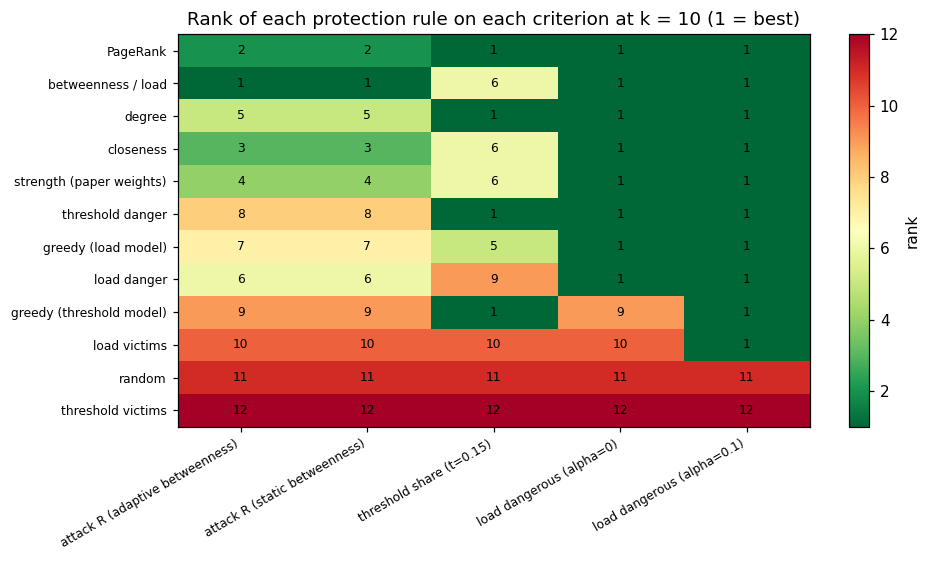

,attack R (adaptive betweenness),attack R (static betweenness),threshold share (t=0.15),load dangerous (alpha=0),load dangerous (alpha=0.1),mean rank
rule,,,,,,
PageRank,2.0,2.0,1.0,1.0,1.0,1.4
betweenness / load,1.0,1.0,6.0,1.0,1.0,2.0
degree,5.0,5.0,1.0,1.0,1.0,2.6
closeness,3.0,3.0,6.0,1.0,1.0,2.8
strength (paper weights),4.0,4.0,6.0,1.0,1.0,3.2
threshold danger,8.0,8.0,1.0,1.0,1.0,3.8
greedy (load model),7.0,7.0,5.0,1.0,1.0,4.2
load danger,6.0,6.0,9.0,1.0,1.0,4.6
greedy (threshold model),9.0,9.0,1.0,9.0,1.0,5.8


In [9]:
k10 = pd.concat([att[(att.k == 10)].merge(cas[cas.k == 10], on=["rule", "k"]), gdf[gdf.k == 10]]).set_index("rule")
crit = {"attack R (adaptive betweenness)": ("R betweenness_adaptive", False), "attack R (static betweenness)": ("R betweenness", False), "threshold share (t=0.15)": ("threshold t=0.15", True), "load dangerous (alpha=0)": ("load alpha=0.0", True), "load dangerous (alpha=0.1)": ("load alpha=0.1", True)}
M10 = pd.DataFrame({name: k10[col] for name, (col, low) in crit.items()})
R10 = pd.DataFrame({name: k10[col].rank(ascending=low, method="min") for name, (col, low) in crit.items()})
R10["mean rank"] = R10.mean(axis=1)
out = M10.join(R10, rsuffix=" (rank)")
fig, ax = plt.subplots(figsize=(9, 5.2))
order = R10.sort_values("mean rank").index
im = ax.imshow(R10.loc[order].drop(columns="mean rank").values, cmap="RdYlGn_r", aspect="auto")
ax.set_xticks(range(len(crit))); ax.set_xticklabels(list(crit), rotation=30, ha="right", fontsize=8); ax.set_yticks(range(len(order))); ax.set_yticklabels(order, fontsize=8)
for i in range(len(order)):
    for j in range(len(crit)): ax.text(j, i, f"{int(R10.loc[order[i]].iloc[j])}", ha="center", va="center", fontsize=8)
ax.set_title("Rank of each protection rule on each criterion at k = 10 (1 = best)"); ax.grid(False); plt.colorbar(im, ax=ax, label="rank"); plt.tight_layout(); plt.show()
display(R10.sort_values("mean rank").style.format("{:.1f}"))

**Reading this.** **No single rule is best everywhere**, but the simple global centralities come out best. Averaged over the four criteria the smallest mean rank belongs to PageRank (1.4), then betweenness/load (2.0), degree (2.6), closeness (2.8) and strength (3.2); the cascade-specific rules (threshold danger, the two greedy rules, load danger) rank 3.8 to 5.8 and the victim rules last (8.2 and 12; threshold victims are no better than random protection, which ranks 11). Because the cascade criteria are nearly saturated (most rules reach zero dangerous origins), the ranking is decided mostly by the attack criteria, where betweenness is first and degree fifth. **Protecting structurally central airports** therefore supports the paper's advice, with a refinement: betweenness and PageRank are slightly better choices than raw degree, and the gateways (ANC, BET, FAI) enter the list through betweenness, whereas rules built from where failures land (victims) should not be used.

## Part D. Budgeted capacity allocation (load cascade)
Rather than making a few airports invulnerable, an operator can add **spare capacity**. We fix a *total* extra capacity E = B x (total initial load) and distribute it by different rules, starting from zero spare capacity everywhere. A uniform proportional allocation with B = 0.2 is exactly the alpha = 0.2 of M9. How large must the budget be before no single airport failure can collapse the network, under each allocation rule?

allocation sweep in 280 s


budget B,0.005000,0.010000,0.020000,0.030000,0.050000,0.075000,0.100000,0.150000,0.200000,0.300000
allocation,,,,,,,,,,
equal absolute amount (additive),36,36,32,25,26,28,23,25,21,16
load victims only (proportional to failure frequency),25,24,20,18,14,10,10,3,6,3
proportional to load (uniform alpha),21,18,17,14,10,5,5,2,1,0
"proportional to load, top-20 loaded airports only",19,17,9,5,2,1,1,0,0,0
"proportional to load, top-40 loaded airports only",20,15,11,8,4,1,1,0,0,0
square of the load (hubs favoured),21,19,17,14,13,9,8,2,2,0


smallest budget in the grid with no dangerous origin: {'proportional to load (uniform alpha)': 0.3, 'equal absolute amount (additive)': None, 'proportional to load, top-20 loaded airports only': 0.15, 'proportional to load, top-40 loaded airports only': 0.15, 'load victims only (proportional to failure frequency)': None, 'square of the load (hubs favoured)': 0.3}


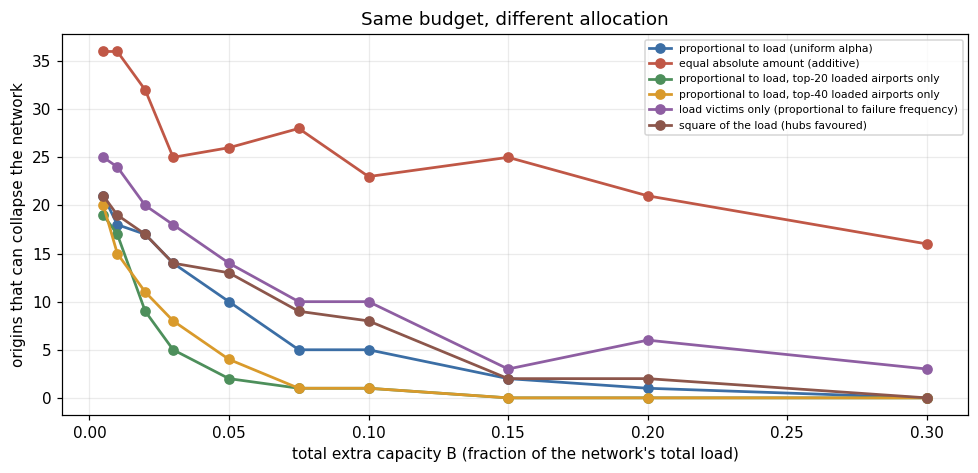

In [10]:
L0 = LC.L0.copy(); totalL = L0.sum()
vict = load_victim.copy()
top20 = np.zeros(N); top20[[idx[n] for n in rules["betweenness / load"][:20]]] = 1
top40 = np.zeros(N); top40[[idx[n] for n in rules["betweenness / load"][:40]]] = 1
rules_alloc = {"proportional to load (uniform alpha)": L0, "equal absolute amount (additive)": np.ones(N), "proportional to load, top-20 loaded airports only": L0 * top20,
               "proportional to load, top-40 loaded airports only": L0 * top40, "load victims only (proportional to failure frequency)": vict + 1e-12, "square of the load (hubs favoured)": L0 ** 2}
budgets = [0.005, 0.01, 0.02, 0.03, 0.05, 0.075, 0.10, 0.15, 0.20, 0.30]
rows = []
t0 = time.time()
for name, w in rules_alloc.items():
    for B in budgets:
        cap = L0 + B * totalL * w / w.sum()
        s_ = EV.summary(cap); rows.append({"allocation": name, "budget B": B, "dangerous origins": s_["dangerous"], "mean LCC / N": s_["mean LCC / N"]})
al_df = pd.DataFrame(rows)
print(f"allocation sweep in {time.time() - t0:.0f} s")
piv = al_df.pivot(index="allocation", columns="budget B", values="dangerous origins")
display(piv.style.background_gradient(cmap="Reds_r", axis=None))
need_B = {name: next((B for B in budgets if piv.loc[name, B] == 0), None) for name in rules_alloc}
print("smallest budget in the grid with no dangerous origin:", need_B)

fig, ax = plt.subplots(figsize=(9, 4.4))
for (name, w), c in zip(rules_alloc.items(), [BLUE, RED, GREEN, ORANGE, PURPLE, BROWN]):
    d = al_df[al_df.allocation == name]; ax.plot(d["budget B"], d["dangerous origins"], "o-", color=c, label=name, lw=1.8)
ax.set_xlabel("total extra capacity B (fraction of the network's total load)"); ax.set_ylabel("origins that can collapse the network"); ax.set_title("Same budget, different allocation"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

**Reading this.** The allocation matters a great deal. For the same total extra capacity, putting it **where the load is** removes the dangerous origins at a much smaller budget than spreading it as an equal absolute amount per airport, which still leaves 16 dangerous origins at B = 0.3 (30% of the total load) and never reaches zero in the grid. Capacity proportional to load reaches zero at B = 0.3 (1 dangerous origin at B = 0.2), capacity proportional to the square of the load also at 0.3, and capacity put **only on the 20 or 40 highest-load airports** (in proportion to their load) reaches zero at B = 0.15; at small budgets the difference is large (B = 0.02: 9 dangerous origins for the top-20 rule against 17 for proportional-to-load and 32 for equal amounts). Allocation by failure frequency (load victims) is inefficient (3 dangerous origins left at B = 0.3). This quantifies M9's qualitative finding that capacity should scale with load, and shows that **concentrating spare capacity on the few highest-load airports is the cheapest way found to make the network safe against any single failure**, in line with the paper's advice to protect hubs, with a measurable price tag.

## Part E. Rewiring: which new routes help?
Suppose m new routes can be added (the network has 2,780; m = 50 is 1.8% more). Candidates are airport pairs within 2,500 km that are not yet connected. Five rules:
- **random**: random candidate pairs (the baseline);
- **low-low**: random pairs where *both* airports are small (degree 5 or less), i.e. regional routes that bypass the hubs;
- **dual-home**: give a randomly chosen single-connection airport a second connection, to the nearest hub it is not yet linked to;
- **gateway bypass**: connect pairs of non-adjacent neighbours of the eight highest-betweenness airports, creating alternatives to them;
- **greedy**: add, one at a time, the route (among 120 random candidates) that most increases the size of the largest component after the ten highest-betweenness airports are removed.

After adding the routes we recompute everything on the new network, including the attacker's ranking.

In [11]:
def eval_graph(H, full=False):
    hn = list(H.nodes); n = H.number_of_nodes()
    out = {}
    cb = rs.attack_curve(H, [], "betweenness", hn); cd = rs.attack_curve(H, [], "degree", hn)
    out["R betweenness"] = rs.robustness_R(cb, n); out["R degree"] = rs.robustness_R(cd, n)
    out["LCC share after top 5% removed"] = cb[round(0.05 * n)] / n
    Ch = cs.Cascade(H)
    for t in (0.10, 0.15):
        need = Ch.need(t); out[f"threshold share t={t:.2f}"] = float(np.mean([Ch.run([i], need)[0].sum() >= 0.5 * n for i in range(n)]))
    if full:
        out["R adaptive betweenness"] = rs.robustness_R(rs.attack_curve(H, [], "betweenness_adaptive", hn), n)
        LCh = lc.LoadCascade(H); R_, _ = LCh.sweep([0.0, 0.1])
        out["load dangerous alpha=0"] = int((R_[:, 0] <= n / 2).sum()); out["load dangerous alpha=0.1"] = int((R_[:, 1] <= n / 2).sum())
    return out

strategies = ["random", "low_low", "dual_home", "gateway_bypass", "greedy"]
ms = (10, 25, 50, 100)
t0 = time.time(); rows = []
base_g = eval_graph(G, full=True); rows.append({"strategy": "none", "m": 0, **base_g})
for strat in strategies:
    for m in ms:
        draws = 1 if strat == "greedy" else 2
        res = []
        for d in range(draws):
            H, _ = rs.add_edges(G, strat, m, np.random.default_rng(100 * d + m), max_km=2500.0)
            res.append(eval_graph(H, full=(m == 50)))
        rows.append({"strategy": strat, "m": m, **{k: np.mean([r[k] for r in res]) for k in res[0] if all(k in r for r in res)}})
rw = pd.DataFrame(rows)
print(f"rewiring experiments in {time.time() - t0:.0f} s")
pv = rw.pivot(index="strategy", columns="m", values="LCC share after top 5% removed")
print("LCC share after the top 5% of airports (by betweenness) are removed; columns = new routes added:")
display(pv.style.format("{:.3f}").background_gradient(cmap="Greens", axis=None))

rewiring experiments in 5778 s
LCC share after the top 5% of airports (by betweenness) are removed; columns = new routes added:


m,0,10,25,50,100
strategy,,,,,
dual_home,nan,0.408,0.404,0.424,0.440
gateway_bypass,nan,0.412,0.422,0.438,0.466
greedy,nan,0.401,0.449,0.457,0.525
low_low,nan,0.409,0.417,0.466,0.500
none,0.401,nan,nan,nan,nan
random,nan,0.415,0.418,0.451,0.497


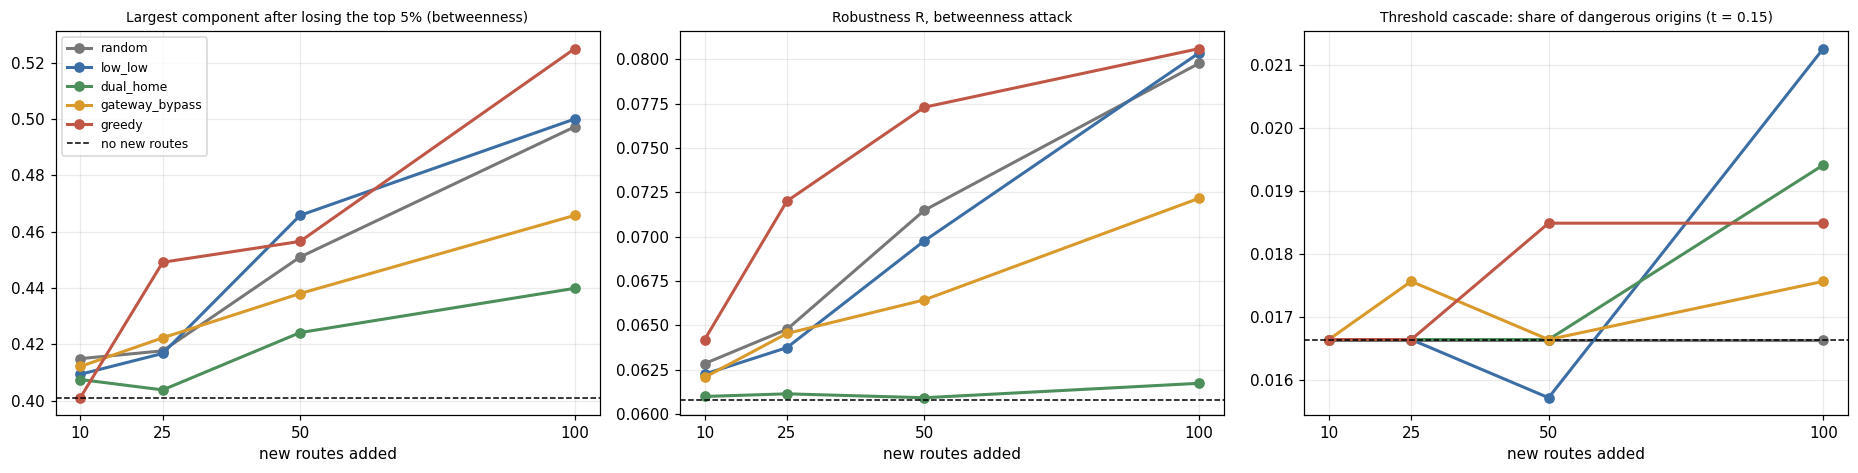

,R betweenness,R adaptive betweenness,LCC share after top 5% removed,threshold share t=0.10,threshold share t=0.15,load dangerous alpha=0,load dangerous alpha=0.1
strategy,,,,,,,
random,0.071,0.041,0.451,0.084,0.017,68.0,5.0
low_low,0.070,0.041,0.466,0.079,0.016,84.5,6.5
dual_home,0.061,0.038,0.424,0.074,0.017,52.0,5.0
gateway_bypass,0.066,0.039,0.438,0.077,0.017,50.0,5.0
greedy,0.077,0.044,0.457,0.074,0.018,85.0,5.0
none (no new routes),0.061,0.036,0.401,0.074,0.017,40.0,5.0


In [12]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
sc_ = {"random": GREY, "low_low": BLUE, "dual_home": GREEN, "gateway_bypass": ORANGE, "greedy": RED}
for ax, col, ttl in [(axes[0], "LCC share after top 5% removed", "Largest component after losing the top 5% (betweenness)"), (axes[1], "R betweenness", "Robustness R, betweenness attack"), (axes[2], "threshold share t=0.15", "Threshold cascade: share of dangerous origins (t = 0.15)")]:
    for strat in strategies:
        d = rw[rw.strategy == strat]; ax.plot(d.m, d[col], "o-", color=sc_[strat], lw=2, label=strat)
    ax.axhline(base_g[col], color="black", ls="--", lw=1, label="no new routes"); ax.set_xlabel("new routes added"); ax.set_title(ttl, fontsize=9); ax.set_xticks(ms)
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()
full = rw[rw.m == 50].set_index("strategy")[["R betweenness", "R adaptive betweenness", "LCC share after top 5% removed", "threshold share t=0.10", "threshold share t=0.15", "load dangerous alpha=0", "load dangerous alpha=0.1"]]
full.loc["none (no new routes)"] = [base_g[c] for c in full.columns]
display(full.style.format({"R betweenness": "{:.3f}", "R adaptive betweenness": "{:.3f}", "LCC share after top 5% removed": "{:.3f}", "threshold share t=0.10": "{:.3f}", "threshold share t=0.15": "{:.3f}", "load dangerous alpha=0": "{:.1f}", "load dangerous alpha=0.1": "{:.1f}"}))

**Reading this.** (Table: 50 new routes, 1.8% more edges; one random draw per rule, so differences of a few thousandths are noise.)
- **Rewiring is far less effective than protection.** The adaptive-attack robustness R is 0.036 without new routes and 0.038 to 0.044 with 50 new routes, against 0.26 to 0.31 when 5 to 10 airports are protected. The reason is structural: the weakness is the dependence of hundreds of small airports on a few hubs and gateways, and a few dozen routes cannot rewire that.
- **Purposeful routes did not clearly beat random ones.** The largest component after the top 5% of airports are removed rises from 0.401 to 0.451 with 50 random routes and 0.466 with 50 low-low routes (the best at m = 50), against 0.424 for dual-homing, 0.438 for gateway bypass and 0.457 for the greedy rule. Only at m = 100 does the greedy rule (0.525) lead, as it is built to, with low-low at 0.500 and random at 0.497. Dual-homing and gateway bypass, which target the critical airports, helped the least on this measure.
- **Rewiring can make the load cascade worse.** Without spare capacity the number of dangerous origins rises from 40 to 50 to 85 with every rule (random 68, low-low 84.5, greedy 85, dual-home 52, gateway bypass 50), and for threshold cascades the share is unchanged or slightly worse (t = 0.10: 0.074 without routes, 0.084 with random routes). New routes change the shortest paths and hence the loads, and with no spare capacity any extra load on an airport makes it fail. Rewiring must be evaluated against the specific failure model, and capacity must be re-planned after the network is changed.

## Part F. Recovery: in which order should airports be restored?
After a failure, restoration takes time. We compare restoration orders for three disasters: the loss of the **top 20 airports by betweenness** (a targeted attack), the top 20 by degree, and the **ORD cascade** of M9 (47 airports failed by overload at alpha = 0.1). Orders: random, by degree, by betweenness (both on the intact network), by strength, and a **greedy** order that always restores the airport that most increases the largest component. The score is the area under the recovery curve (the average size of the largest component during recovery, as a fraction of the intact network): higher is better.

recovery experiments in 1 s


disaster,restoration order,area under recovery curve,restorations to reach 90% of the final size,largest component right after the failure,after full restoration
top 20 by betweenness removed,random,0.747,16,0.490,1.000
top 20 by betweenness removed,by degree,0.751,16,0.490,1.000
top 20 by betweenness removed,by betweenness (load),0.842,12,0.490,1.000
top 20 by betweenness removed,by strength,0.744,16,0.490,1.000
top 20 by betweenness removed,greedy (largest gain first),0.857,10,0.490,1.000
top 20 by degree removed,random,0.854,13,0.652,1.000
top 20 by degree removed,by degree,0.901,8,0.652,1.000
top 20 by degree removed,by betweenness (load),0.906,8,0.652,1.000
top 20 by degree removed,by strength,0.896,8,0.652,1.000
top 20 by degree removed,greedy (largest gain first),0.917,7,0.652,1.000


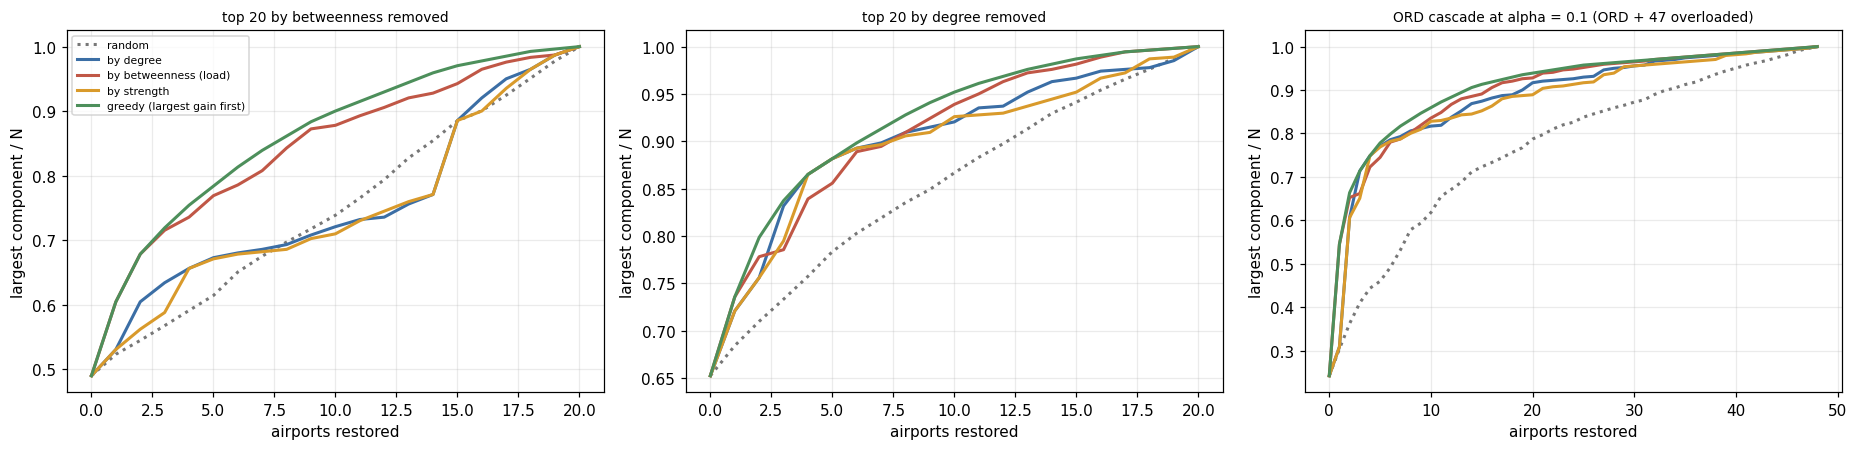

In [13]:
t0 = time.time()
bc_full = pd.Series(LC.L0, index=nodes)
scen = {"top 20 by betweenness removed": rules["betweenness / load"][:20], "top 20 by degree removed": rules["degree"][:20]}
res_ord = LC.run("ORD", LC.capacity(0.1))
scen["ORD cascade at alpha = 0.1 (ORD + 47 overloaded)"] = ["ORD"] + [nodes[i] for f in res_ord["failed_by_round"] for i in f]

orders_rec = lambda failed: {"random": None, "by degree": sorted(failed, key=lambda n: -deg[n]), "by betweenness (load)": sorted(failed, key=lambda n: -bc_full[n]),
                              "by strength": sorted(failed, key=lambda n: -strength[n]), "greedy (largest gain first)": rs.greedy_recovery_order(G, failed)}
rec_rows, rec_curves = [], {}
for sname, failed in scen.items():
    ords = orders_rec(failed); curves = {}
    for oname, o in ords.items():
        if oname == "random":
            cs_ = np.mean([rs.recovery_curve(G, failed, list(np.random.default_rng(s).permutation(failed))) for s in range(30)], axis=0)
        else:
            cs_ = rs.recovery_curve(G, failed, o)
        curves[oname] = cs_
        t90 = next((i for i, v in enumerate(cs_) if v >= 0.9 * cs_[-1]), len(cs_) - 1)
        rec_rows.append({"disaster": sname, "restoration order": oname, "area under recovery curve": float(cs_.mean()), "restorations to reach 90% of the final size": t90, "largest component right after the failure": cs_[0], "after full restoration": cs_[-1]})
    rec_curves[sname] = curves
rec = pd.DataFrame(rec_rows)
print(f"recovery experiments in {time.time() - t0:.0f} s")
display(rec.style.hide(axis="index").format({"area under recovery curve": "{:.3f}", "largest component right after the failure": "{:.3f}", "after full restoration": "{:.3f}"}))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
cc = {"random": GREY, "by degree": BLUE, "by betweenness (load)": RED, "by strength": ORANGE, "greedy (largest gain first)": GREEN}
for ax, (sname, curves) in zip(axes, rec_curves.items()):
    for oname, c_ in curves.items(): ax.plot(range(len(c_)), c_, color=cc[oname], lw=2, label=oname, ls=":" if oname == "random" else "-")
    ax.set_xlabel("airports restored"); ax.set_ylabel("largest component / N"); ax.set_title(sname, fontsize=9)
axes[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

**Reading this.** The **order of restoration matters**, and the best simple rule depends on what failed:
- A **greedy** order (always restore the airport that reconnects the most) is best in every scenario (area under the recovery curve 0.857, 0.917 and 0.903 for the three disasters, as it must be). After the betweenness attack it needs 10 restorations to reach 90% of the final size, against 16 for a random order.
- Among the simple rules, restoring **by betweenness (load)** is the best all-round choice (0.842 against 0.747 for random after the betweenness attack; 0.906 and 0.894 in the other two disasters, slightly above degree at 0.901 and 0.881). Restoring by degree or strength is no better than random after the betweenness attack (0.751 and 0.744 against 0.747), because the gateways that were cutting the network are not the biggest airports.
- The gap between rules shrinks as recovery proceeds and vanishes at full restoration (all end at 1.0); what is gained is time, that is fewer airports restored before most of the network is reconnected.

## Part G. Verdict: is "protect the hubs" right?

In [14]:
def best_by(col, low=False):
    s_ = k10[col]; return s_.idxmin() if low else s_.idxmax()
rp = rec.pivot(index="disaster", columns="restoration order", values="area under recovery curve")
verdict = pd.DataFrame([
    ("(paper) 'protecting key hub airports is important'", "Tested against three failure models with eleven ranking rules, greedy rules, budgeted capacity, rewiring and recovery", "tested"),
    ("Does protecting airports help against targeted attacks?",
     f"Yes, strongly and quickly: protecting the top 10 by betweenness raises R against the adaptive attacker from {base_R['betweenness_adaptive']:.3f} to {att[(att.rule == 'betweenness / load') & (att.k == 10)]['R betweenness_adaptive'].iloc[0]:.3f}; random protection gives {att[(att.rule == 'random') & (att.k == 10)]['R betweenness_adaptive'].iloc[0]:.3f}", "yes"),
    ("Is 'protect the hubs' (by degree) the best rule?",
     f"Close to it, with a refinement: against the adaptive attacker degree gives R = {att[(att.rule == 'degree') & (att.k == 10)]['R betweenness_adaptive'].iloc[0]:.3f} versus {att[(att.rule == 'betweenness / load') & (att.k == 10)]['R betweenness_adaptive'].iloc[0]:.3f} for betweenness; averaged over four criteria PageRank is first ({R10['mean rank'].sort_values().iloc[0]:.1f}), betweenness/load second, degree third", "supported; betweenness or PageRank slightly better"),
    ("Does one protection rule work for every failure model?",
     "No: the best rule differs between attack, threshold cascade and load cascade (rank matrix), although the simple global centralities are near the top everywhere; victim-based rules are no better than random", "no single best rule"),
    ("How much capacity is needed?",
     f"Allocation matters: smallest budget with no dangerous origin, by rule: " + "; ".join(f"{k.split(' (')[0]}: {v}" for k, v in need_B.items()), "concentrate capacity on high-load airports"),
    ("Does adding routes help as much as protecting airports?",
     "No: 50 new routes lift adaptive-attack R from 0.036 to at most 0.044, hardening 10 airports to 0.26 to 0.31; the new routes also raise the number of dangerous load-cascade origins from 40 to 50-85", "rewiring is the weaker lever"),
    ("In what order should airports be restored?",
     "Greedy (largest gain first) is best; among simple rules, by betweenness/load is the best all-round choice", "restore gateways first"),
], columns=["question", "what we find", "status"])
verdict.style.hide(axis="index").format(escape="html").set_properties(subset=["question", "what we find"], **{"text-align": "left", "white-space": "normal"})

question,what we find,status
(paper) 'protecting key hub airports is important',"Tested against three failure models with eleven ranking rules, greedy rules, budgeted capacity, rewiring and recovery",tested
Does protecting airports help against targeted attacks?,"Yes, strongly and quickly: protecting the top 10 by betweenness raises R against the adaptive attacker from 0.036 to 0.309; random protection gives 0.063",yes
Is 'protect the hubs' (by degree) the best rule?,"Close to it, with a refinement: against the adaptive attacker degree gives R = 0.288 versus 0.309 for betweenness; averaged over four criteria PageRank is first (1.4), betweenness/load second, degree third",supported; betweenness or PageRank slightly better
Does one protection rule work for every failure model?,"No: the best rule differs between attack, threshold cascade and load cascade (rank matrix), although the simple global centralities are near the top everywhere; victim-based rules are no better than random",no single best rule
How much capacity is needed?,"Allocation matters: smallest budget with no dangerous origin, by rule: proportional to load: 0.3; equal absolute amount: None; proportional to load, top-20 loaded airports only: 0.15; proportional to load, top-40 loaded airports only: 0.15; load victims only: None; square of the load: 0.3",concentrate capacity on high-load airports
Does adding routes help as much as protecting airports?,"No: 50 new routes lift adaptive-attack R from 0.036 to at most 0.044, hardening 10 airports to 0.26 to 0.31; the new routes also raise the number of dangerous load-cascade origins from 40 to 50-85",rewiring is the weaker lever
In what order should airports be restored?,"Greedy (largest gain first) is best; among simple rules, by betweenness/load is the best all-round choice",restore gateways first


## Checks

In [15]:
rb = att[(att.rule == "betweenness / load")].set_index("k"); rr = att[(att.rule == "random")].set_index("k")
checks = [
    ("nothing protected reproduces M5 (adaptive R) and M9 (5 dangerous origins)", abs(rs.robustness_R(base_adapt, N) - 0.0365) < 0.002 and base_summary["dangerous"] == 5),
    ("protecting 5 betweenness airports lifts adaptive-attack R by at least 3x", rb.loc[5, "R betweenness_adaptive"] > 3 * base_R["betweenness_adaptive"]),
    ("informed protection beats random protection at every budget (adaptive attacker)", all(rb.loc[k, "R betweenness_adaptive"] > rr.loc[k, "R betweenness_adaptive"] for k in ks)),
    ("more protection never hurts (betweenness rule, static attacker)", all(rb.loc[ks[i + 1], "R betweenness"] >= rb.loc[ks[i], "R betweenness"] for i in range(len(ks) - 1))),
    ("protecting the top-load airports removes the dangerous origins of the load cascade with no spare capacity", cas[(cas.rule == "betweenness / load") & (cas.k == 20)]["load alpha=0.0"].iloc[0] < base_load["load alpha=0.0"] / 4),
    ("the best simple rule is not the same for every criterion", len({R10[c].idxmin() for c in crit}) > 1),
    ("proportional capacity needs a smaller budget than equal-absolute capacity", (need_B["proportional to load (uniform alpha)"] or 1e9) <= (need_B["equal absolute amount (additive)"] or 1e9)),
    ("recovery: greedy is the best order in every scenario", all(rec[rec.disaster == d].set_index("restoration order")["area under recovery curve"].idxmax() == "greedy (largest gain first)" for d in scen)),
    ("recovery: any informed order beats random in every scenario", all(rec[rec.disaster == d].set_index("restoration order")["area under recovery curve"]["by betweenness (load)"] >= rec[rec.disaster == d].set_index("restoration order")["area under recovery curve"]["random"] - 1e-9 for d in scen)),
    ("rewiring with 50 routes changes the top-5% LCC share by less than protection of 10 airports changes R", abs(rw[(rw.strategy == "greedy") & (rw.m == 50)]["R betweenness"].iloc[0] - base_g["R betweenness"]) < rb.loc[10, "R betweenness"] - base_R["betweenness"]),
]
failed = [lab for lab, ok in checks if not ok]
print(f"{len(checks) - len(failed)} of {len(checks)} checks passed")
assert not failed, failed
print("All M11 assertions passed.")

10 of 10 checks passed
All M11 assertions passed.


## Summary and take-aways

- **The paper's advice holds and can be sharpened.** Protecting the top 10 airports by betweenness lifts the adaptive-attack robustness index from 0.036 to 0.31 (random protection 0.06); degree gives 0.29. Averaged over attack, threshold cascade and load cascade, PageRank (mean rank 1.4), betweenness (2.0) and degree (2.6) are the best rules.
- **Cascades are cheap to defend.** 10 protected airports by degree or PageRank remove every threshold-cascade origin that collapses the network (9 of 541 at t = 0.15); 5 airports remove all 40 load-cascade origins at zero spare capacity (partly by construction, since protected airports cannot be origins).
- **Rules built from where failures land are useless.** The victim rules (threshold victims, load victims) are no better than random protection against attacks, and threshold victims do nothing against the cascades; greedy model-specific rules do not beat the simple centralities.
- **Capacity.** For a given total extra capacity, concentrating it on the top 20 to 40 highest-load airports removes every dangerous origin at B = 0.15 against B = 0.3 for proportional allocation; equal amounts never get there in the grid.
- **Rewiring is the weaker lever and can backfire.** 50 new routes lift adaptive R only to 0.038-0.044, the purposeful rules did not clearly beat random routes at m = 50, and every rule increased the number of dangerous load-cascade origins from 40 to 50-85.
- **Recovery.** Greedy restoration is best; among simple orders restore by betweenness first (area 0.842 against 0.747 for random after losing the top 20 by betweenness); restoring by degree is no better than random there.
- **Caveats.** Protection is idealised (free, perfect); one random draw per rewiring rule; the greedy searches use restricted candidate sets; single failures and the three models of this project only.